# 00 · Results overview

All experiments at a glance. This notebook only **reads** the run folders (`runs/*/config.json` and
`metrics.json`), so it updates itself: re-run it after every new experiment.

| Folder | Notebooks |
|---|---|
| `notebooks/data/` | 01 EDA · 02 data quality · 03 split · 04 haze correction · 05 Fourier analysis · 06 Kaggle confidence · 07 topological features · 08 vegetation shift · 09 label convention |
| `notebooks/experiments/` | E01 baseline · E02 hist_split · E03 AdaBN · E04 contrast aug · E05 Fourier (a–c) · E06 pseudo-labelling (a–c) · E07 shape-focused input (a–b) · E08 weight averaging (a–b) · E09 pseudo-labels round 3 (a–b) · E10 small track (≤ 1M) · E11 two-branch network · E12 pseudo-labels round 4 |

Notebooks E05–E09 contain several variants each (`E05a`, `E05b`, …); the `variant` column names them.

**The task in one sentence:** the training images (EuroSAT, Level-1C) contain haze, the Kaggle test
images (Level-2A) are atmospherically corrected, so a model that reaches 99% on EuroSAT scores far
lower on Kaggle. Every experiment tries to close that gap.

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
sys.path.insert(0, str(ROOT))
from src.data import PROJECT_ROOT
from src.plot_style import MUTED, TEST_COLOR, TRAIN_COLOR, apply_style

apply_style()

rows = []
for run in sorted((PROJECT_ROOT / "runs").iterdir()):
    if not (run / "metrics.json").exists():
        continue
    config = json.loads((run / "config.json").read_text())
    metrics = json.loads((run / "metrics.json").read_text())
    notebook = config.get("notebook", "?")
    rows.append({
        "notebook": notebook,
        "variant": config.get("variant", notebook.split("_")[0]),
        "description": config.get("description", run.name),
        "internal test (%)": (metrics.get("internal_test_acc") or np.nan) * 100,
        "Kaggle public (%)": (metrics.get("kaggle_public_score") or np.nan) * 100,
        "parameters": config.get("n_params"),
        "base_run": Path(config["base_run"]).name if "base_run" in config else None,
        "run": run.name,
    })
    # Models kept inside a run folder (E08b: checkpoints, EMA, SWA), each with its own metrics
    for sub in sorted((run / "variants").glob("*/metrics.json")) if (run / "variants").exists() else []:
        m = json.loads(sub.read_text())
        rows.append({**rows[-1], "description": f"{config.get('description', run.name)} · {sub.parent.name}",
                     "internal test (%)": (m.get("internal_test_acc") or np.nan) * 100,
                     "Kaggle public (%)": (m.get("kaggle_public_score") or np.nan) * 100,
                     "run": f"{run.name}/variants/{sub.parent.name}"})
runs = pd.DataFrame(rows)
# Order: by experiment notebook, a base model before its AdaBN version
runs = runs.assign(_adabn=runs["base_run"].notna()).sort_values(["notebook", "variant", "_adabn", "run"]) \
           .drop(columns="_adabn").reset_index(drop=True)
print(f"{len(runs)} runs, {runs['Kaggle public (%)'].notna().sum()} submitted to Kaggle")

44 runs, 24 submitted to Kaggle


## 1 · All runs

In [2]:
table = runs.drop(columns=["run", "base_run"]).copy()
table["internal test (%)"] = table["internal test (%)"].round(2)
table["Kaggle public (%)"] = table["Kaggle public (%)"].round(2)
best = runs["Kaggle public (%)"].idxmax()
print(f"Best Kaggle public score: {runs.loc[best, 'Kaggle public (%)']:.2f}%  ({runs.loc[best, 'run']})")
table.style.format(precision=2, na_rep="–").hide(axis="index")

Best Kaggle public score: 72.67%  (2026-10-15_1829_pl_r3_view_agree_contrast_aug_hist_split_effb0)


notebook,variant,description,internal test (%),Kaggle public (%),parameters
E01_baseline,E01,"EfficientNet-B0, 12 bands, no correction",98.79,56.48,4022950.00
E02_hist_split,E02,+ histogram matching of training images (hist_split),98.64,64.06,4022950.00
E03_adabn,E03,E02 + AdaBN on all Kaggle images,–,–,4022950.00
E03_adabn,E03,E02 + AdaBN balanced (water share matched),–,65.28,4022950.00
E04_contrast_aug,E04,hist_split + contrast/brightness augmentation,98.77,64.39,4022950.00
E04_contrast_aug,E04,hist_split + contrast/brightness augmentation + AdaBN balanced,–,68.18,4022950.00
E05_fourier,E05a,E04 + Fourier A: FDA augmentation,98.79,–,4022950.00
E05_fourier,E05a,E04 + Fourier A: FDA augmentation + AdaBN balanced,–,66.26,4022950.00
E05_fourier,E05b,E04 + Fourier B: spectral matching of training images,98.57,–,4022950.00
E05_fourier,E05b,E04 + Fourier B: spectral matching + AdaBN balanced,–,67.85,4022950.00


## 2 · Kaggle score per experiment

Submitted runs by experiment (a base model before its AdaBN version). The dashed line is the baseline. The public
leaderboard uses about half of the test images, so differences below about 1 point are within noise.

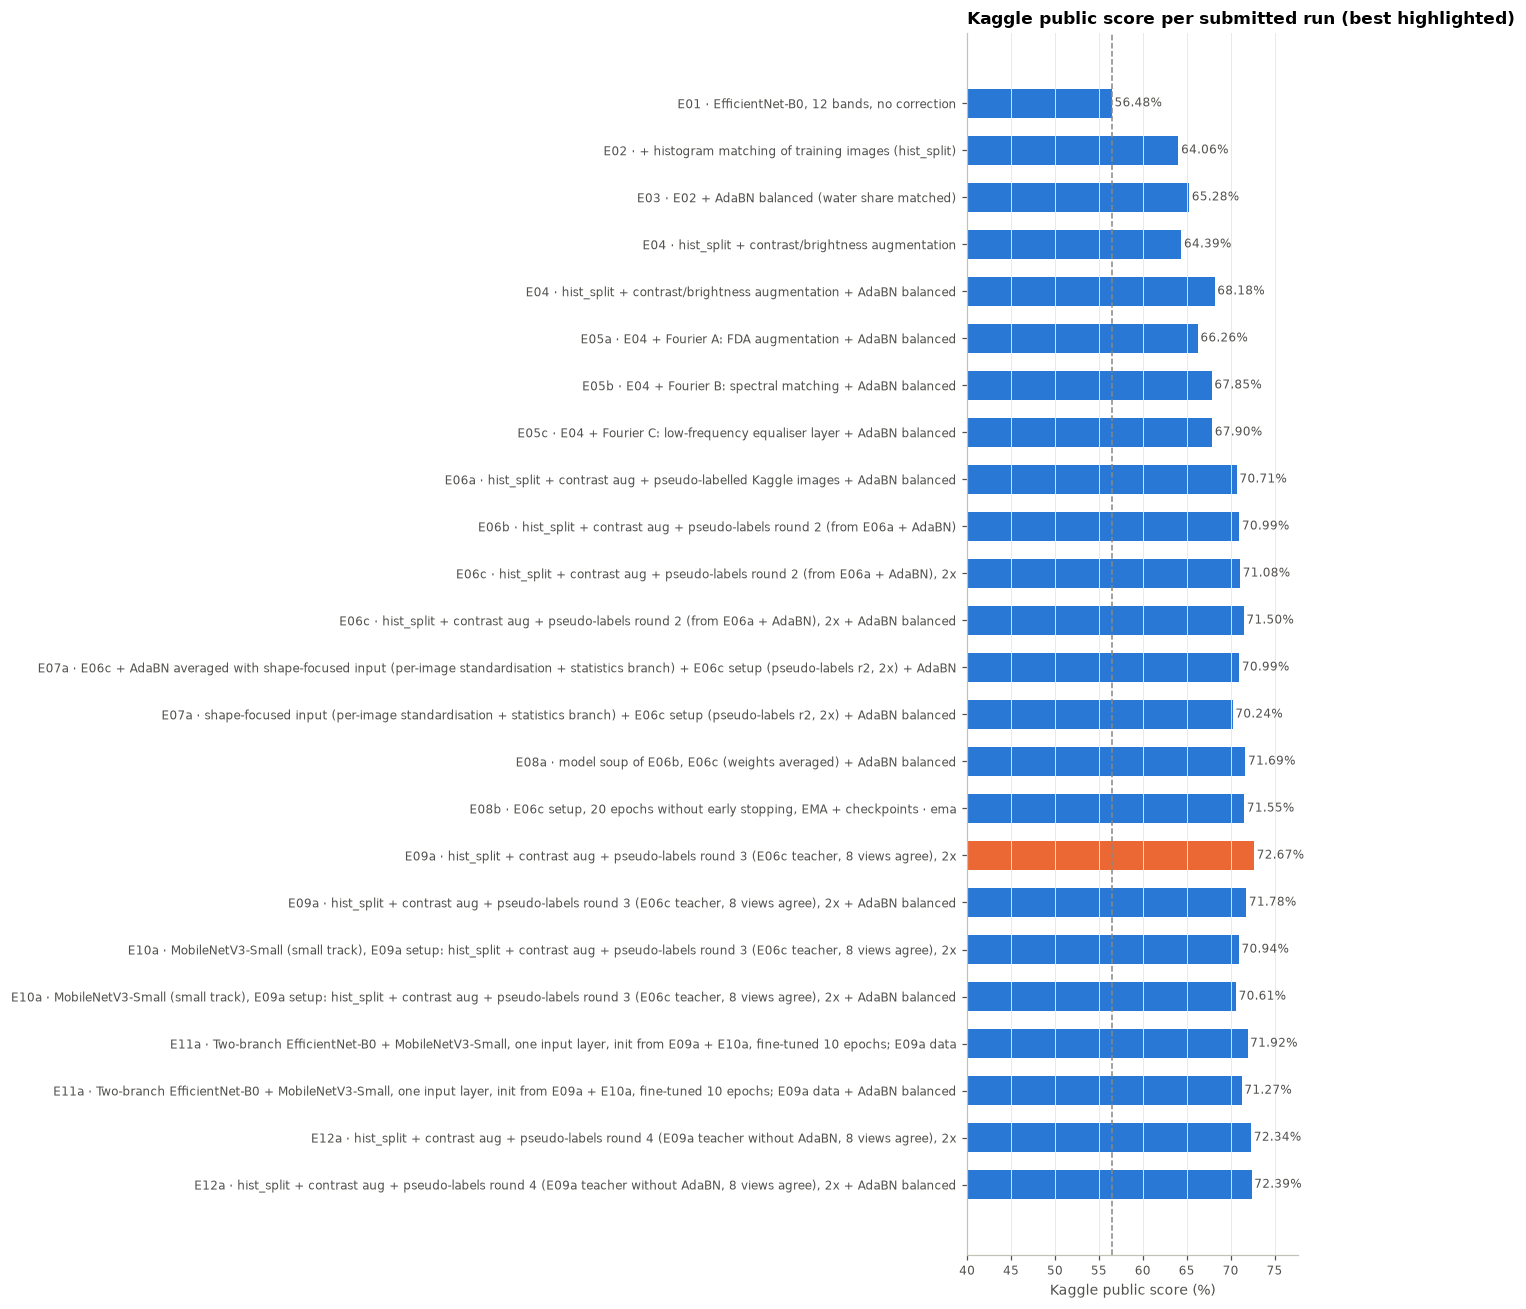

In [3]:
sub = runs.dropna(subset=["Kaggle public (%)"]).reset_index(drop=True)
labels = [f"{v} · {d}" for v, d in zip(sub["variant"], sub["description"])]
y = np.arange(len(sub))[::-1]
colors = [TEST_COLOR if i == sub["Kaggle public (%)"].idxmax() else TRAIN_COLOR for i in range(len(sub))]

fig, ax = plt.subplots(figsize=(12, 0.45 * len(sub) + 1.2))
ax.barh(y, sub["Kaggle public (%)"], color=colors, height=0.62)
for yi, v in zip(y, sub["Kaggle public (%)"]):
    ax.text(v + 0.3, yi, f"{v:.2f}%", va="center", fontsize=8, color="#52514e")
baseline = sub.loc[sub["notebook"] == "E01_baseline", "Kaggle public (%)"].iloc[0]
ax.axvline(baseline, color=MUTED, ls="--", lw=1)
ax.set_yticks(y, labels, fontsize=8)
ax.set_xlim(40, max(sub["Kaggle public (%)"]) + 5)
ax.set_xlabel("Kaggle public score (%)")
ax.set_title("Kaggle public score per submitted run (best highlighted)", loc="left")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

## 3 · The domain gap

For every submitted model: accuracy on the internal EuroSAT test split vs the Kaggle score. The models
learn EuroSAT almost perfectly; everything between the two dots is lost to the Level-1C → Level-2A shift.
AdaBN versions have no internal test score of their own (their statistics are adapted to the Kaggle
images), so the value of their base model is shown, marked with "(base)".

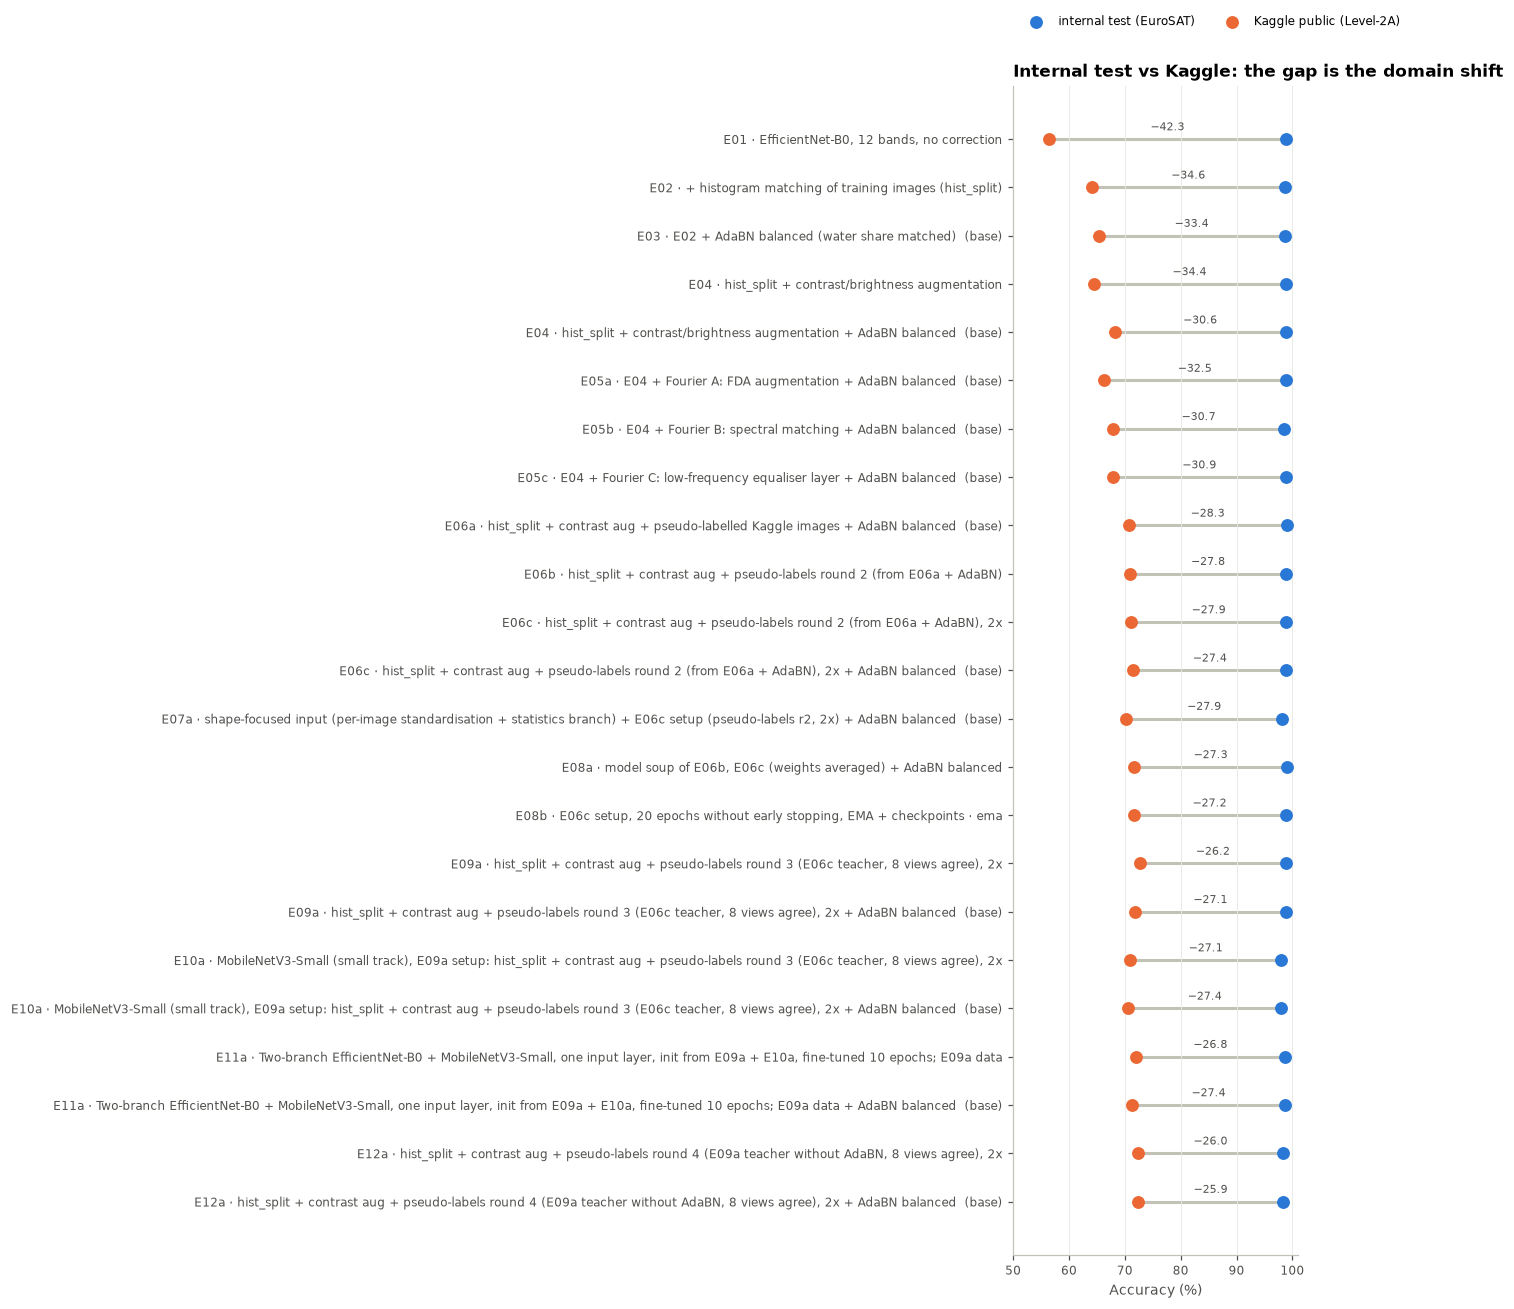

In [4]:
internal = dict(zip(runs["run"], runs["internal test (%)"]))
gap = runs.dropna(subset=["Kaggle public (%)"]).copy()
gap["internal"] = [internal[b] if isinstance(b, str) else v for b, v in zip(gap["base_run"], gap["internal test (%)"])]
gap = gap.dropna(subset=["internal"])   # ensembles have no internal test score
gap["label"] = [f"{v} · {d}" + ("  (base)" if isinstance(b, str) else "")
                for v, d, b in zip(gap["variant"], gap["description"], gap["base_run"])]
gap = gap.reset_index(drop=True)

fig, ax = plt.subplots(figsize=(12, 0.45 * len(gap) + 1.6))
yy = np.arange(len(gap))[::-1]
ax.hlines(yy, gap["Kaggle public (%)"], gap["internal"], color="#c3c2b7", lw=2, zorder=1)
ax.scatter(gap["internal"], yy, color=TRAIN_COLOR, s=55, zorder=2, label="internal test (EuroSAT)")
ax.scatter(gap["Kaggle public (%)"], yy, color=TEST_COLOR, s=55, zorder=2, label="Kaggle public (Level-2A)")
for yi, k, i in zip(yy, gap["Kaggle public (%)"], gap["internal"]):
    ax.text((k + i) / 2, yi + 0.18, f"−{i - k:.1f}", ha="center", fontsize=7, color="#52514e")
ax.set_yticks(yy, gap["label"], fontsize=8)
ax.set_xlim(50, 101)
ax.set_xlabel("Accuracy (%)")
ax.set_title("Internal test vs Kaggle: the gap is the domain shift", loc="left")
ax.legend(loc="lower left", bbox_to_anchor=(0, 1.04), ncol=2, fontsize=8)
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

## 4 · What we learned

1. **The problem is the data shift, not the model.** Every model reaches about 98.8% on EuroSAT but loses
   30–40 points on Kaggle. Bigger models would not help; handling the shift does.
2. **The Kaggle set has about twice as much water** (23.5% vs 9%). Every method that takes statistics from
   the Kaggle images fails if it ignores this: normalising Kaggle images with their own statistics
   (47.82%, tried in `E01_baseline`), plain histogram matching (turns vegetation into "water"),
   AdaBN on all Kaggle images (`E03_adabn`). Matching the water share fixed each of them.
3. **Haze correction by histogram matching is the biggest single step** (+7.6 points, `E02`). After it,
   brightness and colour of training and test images are statistically indistinguishable (`04_haze_correction`).
4. **Contrast within images remains.** Contrast augmentation alone barely helps (+0.3), AdaBN alone
   +1.2, **both together +4.1** over `E02` (`E04`): the contrast-trained model copes much better with
   AdaBN's adjusted statistics.
5. **Not every measurable difference matters.** The detail profile (spectrum) separates training and test
   images almost perfectly (`05_fourier_analysis`), and spectral matching removes it, but the score does
   not change (`E05b`). The CNN already ignores it. FDA (`E05a`) even hurts.
6. **Label-free measurements** (confidence, view agreement, predicted class mix) predicted the direction of
   most changes, but not their size; only Kaggle settles close calls.
7. **Learning from the test images works best now.** The remaining errors sit in the vegetation/crop classes and in
   mixed scenes (`06_kaggle_confidence`). Pseudo-labelling (`E06`), with the same number of images per class, added
   +2.5 points in round 1 and +0.8 in round 2 (71.50%).
8. **Shapes transfer better than band values, but that doesn't make a better input.** Topological features are more
   alike in both domains (`07_topological_features`), yet a shape-focused input (`E07a`) and topological features (`E07b`)
   both lowered the score: absolute brightness is still useful after all corrections.
9. **Averaging independent runs helps a little:** the model soup of E06b + E06c (`E08a`, 71.69%) beat both members;
   averaging within one run (EMA, SWA) or training fewer epochs (`E08b`) does not help.
10. **Label-free measures compare models of the same kind well (E06a → E06c), but not models with different
    inputs** (`E07a` looked better than E06c and scored 1.3 points lower).
11. **Pseudo-labelling saturates after round 3.** All images whose 8 views agree, from a single teacher (`E09a`), give
    the best model: **72.67% without AdaBN**. Round 4 with E09a as teacher (`E12a`, 72.34%) adds 263 images but
    changes no label; the student only re-learns the teacher. Soft labels (`E09b`) mostly copy the teacher.
12. **AdaBN stops helping once enough Kaggle images are in training.** It helped up to E06c (+0.4), but cost
    0.3–0.9 points for every model trained on the round-3 pseudo-labels (`E09a`, `E10a`, `E11a`): BatchNorm already
    carries Kaggle statistics. Every new model is submitted both ways.
13. **Kaggle labels mixed scenes like EuroSAT** (`09_label_convention`). Switching River images with 10–30% water to
    their vegetation second choice lost about 13 public images. The remaining errors are in the vegetation and crop
    classes without water.
14. **Small track (≤ 1M):** MobileNetV3-Small with a one-layer head (934k parameters, `E10a`) scores 70.94%, only
    1.7 points below the best 4M model. A two-branch network of both (`E11a`, one input layer, 4.96M) falls back
    to its EfficientNet branch and scores 71.92%, below E09a alone.